<a href="https://colab.research.google.com/github/andreasantalla/ASE-GIS/blob/main/ps3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# [ps3] Is Comunidad Garces located where the need is?

*Run order note: the setup block (Section 0) and the "Build map datasets" cell must run first, because later sections depend on them. Everything after that reads top to bottom in the narrative order.*

## **0. Setup (run first)**

In [ ]:
!pip install adjustText contextily -q

In [ ]:
# ===== Imports =====
import os, zipfile
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.geometry import Point
import mapclassify
import numpy as np
import textwrap
import matplotlib.patheffects as pe
from adjustText import adjust_text
import requests
import json
import folium
import io
from PIL import Image

gpd.__version__

'1.2.0'

Philadelphia 2015-vintage tract count: 384


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

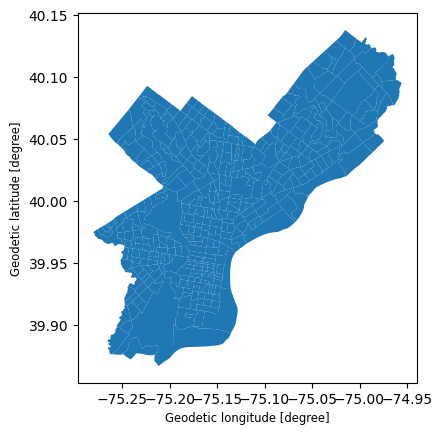

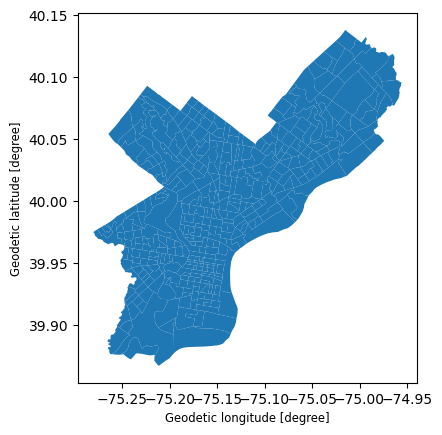

In [ ]:
# ===== Load 2015-vintage Philly tracts (matches CDC PLACES em5e-5hvn boundary vintage) =====
!wget -q -O phl_tracts_2015.zip "https://github.com/andreasantalla/ASE-GIS/raw/refs/heads/main/tl_2015_42_tract.zip"
zipfile.ZipFile('phl_tracts_2015.zip', 'r').extractall()

pa_tracts_2015 = gpd.read_file('tl_2015_42_tract.shp')
phT_2015 = pa_tracts_2015[pa_tracts_2015['COUNTYFP'] == '101'][['GEOID', 'NAME', 'geometry']].copy()
phT_2015['GEOID'] = phT_2015['GEOID'].astype(str)
phT_2015.plot()  # sanity check
print(f"Philadelphia 2015-vintage tract count: {len(phT_2015)}")  # should be 384


# ===== Load 2020-vintage Philly tracts (matches ACS 2022 5-year boundaries) =====
!wget -q -O phl_tracts_2020.zip "https://www2.census.gov/geo/tiger/TIGER2020/TRACT/tl_2020_42_tract.zip"
zipfile.ZipFile('phl_tracts_2020.zip', 'r').extractall()

pa_tracts = gpd.read_file('tl_2020_42_tract.shp')
phT = pa_tracts[pa_tracts['COUNTYFP'] == '101'][['GEOID', 'NAME', 'geometry']].copy()
phT['GEOID'] = phT['GEOID'].astype(str)
phT.plot()  # sanity check: should look like Philadelphia

In [ ]:
# ===== Comunidad Garces location =====
garces_lat, garces_lon = 39.9249, -75.1601
garces_point = gpd.GeoSeries([Point(garces_lon, garces_lat)], crs='EPSG:4326')
garces_point_proj = garces_point.to_crs(epsg=2272)   # PA State Plane, feet
buffer_1mi = garces_point_proj.buffer(5280).to_crs(epsg=4326)  # 1 mile
buf = buffer_1mi.iloc[0]

# ===== Neighborhoods =====
neigh = gpd.read_file(
    "https://raw.githubusercontent.com/opendataphilly/odp-data-storage/refs/heads/master/philadelphia-neighborhoods/philadelphia-neighborhoods.geojson"
).to_crs(epsg=4326)
neigh['label_pt'] = neigh.geometry.representative_point()

keep = [
    # in/around the 1-mile buffer (the neighborhoods your interpretation talks about)
    'Passyunk Square', 'East Passyunk', 'Bella Vista', 'Newbold', 'Whitman',
    'Point Breeze', 'Pennsport', 'Queen Village', 'Dickinson Narrows',
    'Lower Moyamensing', 'Girard Estates', 'Hawthorne', 'Graduate Hospital',
    'West Passyunk', 'Packer Park', 'Greenwich',
    # orientation anchors
    'Rittenhouse', 'Society Hill', 'Old City', 'Riverfront', 'Washington Square West',
]

# ===== Bivariate color key (income across, need up) =====
bivariate_colors = {
    (0, 0): '#e8e8e8', (1, 0): '#b0d5df', (2, 0): '#64acbe',   # low-need row
    (0, 1): '#e4acac', (1, 1): '#ad9ea5', (2, 1): '#627f8c',   # mid-need row
    (0, 2): '#c85a5a', (1, 2): '#985356', (2, 2): '#574249',   # high-need row
}

In [ ]:
# ===== Reusable functions =====
def pull_acs_table_from_github(url, variables, fname):
    """Downloads a pre-saved ACS JSON from GitHub, returns a tidy dataframe with GEOID."""
    os.system(f'wget -q -O {fname} "{url}"')

    df = pd.read_json(fname)
    df.columns = df.iloc[0]
    df = df[1:].reset_index(drop=True)
    for col in variables:
        df[col] = pd.to_numeric(df[col])
    df['GEOID'] = df['state'] + df['county'] + df['tract']
    return df


def pull_places_from_api(county_fips, measure_id, release_resource="em5e-5hvn"):
    # Queries CDC PLACES census-tract-level data from the Socrata API.
    # release_resource "em5e-5hvn" = PLACES Census Tract Data, 2023 release (opendata format)
    # Returns a tidy dataframe with GEOID (=LocationID, 11-digit tract FIPS) and the measure value.
    url = (f"https://data.cdc.gov/resource/{release_resource}.json"
           f"?countyfips={county_fips}&measureid={measure_id}&$limit=500")
    df = pd.read_json(url)
    df = df.rename(columns={'locationid': 'GEOID', 'data_value': measure_id.lower()})
    df['GEOID'] = df['GEOID'].astype(str)
    df[measure_id.lower()] = pd.to_numeric(df[measure_id.lower()], errors='coerce')
    return df[['GEOID', measure_id.lower(), 'totalpopulation']]


def add_pct_foreign_born(df):
    df['pct_foreign_born'] = np.where(df['B05002_001E'] > 0,
                                      100 * df['B05002_013E'] / df['B05002_001E'],
                                      np.nan)   # undefined where population = 0
    return df


def add_foreign_born_bubbles(ax, gdf_4326, col='pct_foreign_born', scale=3, zorder=4):
    """Proportional circles at tract centroids, sized by % foreign-born."""
    g = gdf_4326.dropna(subset=[col]).copy()
    cent = g.to_crs(epsg=2272).centroid.to_crs(epsg=4326)   # centroids in projected CRS
    ax.scatter(cent.x, cent.y, s=g[col] * scale, facecolor='white', alpha=0.55,
               edgecolor='black', linewidth=0.6, zorder=zorder)


def foreign_born_legend_handles(scale=3, levels=(5, 20, 40)):
    # scatter's s is area in pt^2, Line2D's markersize is a diameter in pt -> sqrt
    return [Line2D([0], [0], marker='o', linestyle='', markerfacecolor='white',
                   markeredgecolor='black', markersize=np.sqrt(v * scale),
                   label=f'{v}% foreign-born') for v in levels]


def stack(label, width=10):
    return textwrap.fill(label, width=width)


def add_neighborhood_labels(ax, xlim, ylim, names=None, name_col='MAPNAME', fontsize=6):
    neigh.plot(ax=ax, color='none', edgecolor='black', linewidth=1.2, zorder=3)

    in_view = neigh[neigh['label_pt'].apply(
        lambda p: xlim[0] < p.x < xlim[1] and ylim[0] < p.y < ylim[1])]
    if names is not None:
        in_view = in_view[in_view[name_col].isin(names)]

    texts = []
    for _, row in in_view.iterrows():
        t = ax.text(row['label_pt'].x, row['label_pt'].y, stack(row[name_col]),
                    ha='center', va='center', multialignment='center',
                    fontsize=fontsize, fontweight='bold', zorder=6, linespacing=0.9,
                    path_effects=[pe.withStroke(linewidth=2, foreground='white')])
        texts.append(t)
    return texts


def add_scatter(ax2, valid, var, ylabel, hlines, title):
    """Income vs `var` scatter, colored like the map. hlines = class cutoffs for `var`."""
    in_buffer = valid.intersects(buffer_1mi.iloc[0])

    ax2.scatter(valid['median_hh_income'], valid[var],
                c=valid['biv_color'], s=15 + valid['pct_foreign_born'].fillna(0) * 1.5,
                edgecolor=np.where(in_buffer, 'blue', 'black'),
                linewidth=np.where(in_buffer, 1.5, 0.4), alpha=0.9)

    for x in (57350, 91750):
        ax2.axvline(x, color='gray', linestyle='--', linewidth=0.8)
    for y in hlines:
        ax2.axhline(y, color='gray', linestyle=':', linewidth=0.8)

    ax2.set_xlabel('Median household income ($)')
    ax2.set_ylabel(ylabel)
    ax2.set_title(f'{title}\n(blue outline = within 1 mile; size = % foreign-born)', fontsize=9)
    ax2.xaxis.set_major_formatter(lambda x, _: f'${x/1000:.0f}k')
    plt.tight_layout()


def plot_tercile_bivariate(df, var, title, key_ylabel, ylabel):
    """Tercile-classified `var` x HUD AMI income band, with buffer, bubbles, neighborhoods, scatter."""
    d = df.to_crs(epsg=4326)
    valid = d.dropna(subset=[var, 'median_hh_income']).copy()
    missing = d[d[var].isna() | d['median_hh_income'].isna()]

    q33, q66 = valid[var].quantile([0.33, 0.66])
    valid['var_class'] = np.select([valid[var] < q33, valid[var] < q66], [0, 1], default=2)
    valid['income_class'] = np.select([valid['median_hh_income'] < 57350,
                                       valid['median_hh_income'] < 91750], [0, 1], default=2)
    valid['biv_color'] = valid.apply(
        lambda r: bivariate_colors[(r['income_class'], r['var_class'])], axis=1)

    xlim = (garces_lon - 0.025, garces_lon + 0.045)
    ylim = (garces_lat - 0.02, garces_lat + 0.03)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={'width_ratios': [1, 0.9]})

    missing.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.5, hatch='///')
    valid.plot(ax=ax, color=valid['biv_color'], edgecolor='black', linewidth=0.4)
    add_foreign_born_bubbles(ax, valid, scale=3)

    buffer_1mi.plot(ax=ax, color='none', edgecolor='blue', linewidth=1.8, linestyle='--', zorder=4)
    ax.scatter(garces_lon, garces_lat, marker='o', color='yellow', s=90, zorder=5, edgecolor='black')
    add_neighborhood_labels(ax, xlim, ylim, names=keep)
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.set_title(title)
    ax.axis('off')

    point = Line2D([0], [0], label='Comunidad Garces', marker='o', markersize=8,
                   markeredgecolor='black', markerfacecolor='yellow', linestyle='')
    buffer_handle = Line2D([0], [0], label='1-mile radius', color='blue', linewidth=1.8, linestyle='--')
    neigh_handle = Line2D([0], [0], label='Neighborhood boundary', color='black', linewidth=1.2)
    no_data = Line2D([0], [0], label='Special land use', marker='s', markersize=8,
                     markerfacecolor='lightgray', markeredgecolor='black', linestyle='')
    ax.legend(handles=[point, buffer_handle, neigh_handle, no_data] + foreign_born_legend_handles(scale=3),
              loc='lower right', fontsize=6)

    legend_ax = ax.inset_axes([0.78, 0.55, 0.20, 0.20])
    for i in range(3):
        for v in range(3):
            legend_ax.add_patch(plt.Rectangle((i, v), 1, 1, color=bivariate_colors[(i, v)]))
    legend_ax.set_xlim(0, 3); legend_ax.set_ylim(0, 3)
    legend_ax.set_xticks([]); legend_ax.set_yticks([])
    legend_ax.set_xlabel('<50% | 50-80% | >80%\nAMI', fontsize=6)
    legend_ax.set_ylabel(key_ylabel, fontsize=6)
    legend_ax.set_title('Bivariate Key', fontsize=9)

    view = valid.cx[xlim[0]:xlim[1], ylim[0]:ylim[1]]     # tracts that appear in the zoomed map
    add_scatter(ax2, view, var, ylabel, hlines=(q33, q66),
                title=f'Income vs. {ylabel.replace("% ", "")}, Tracts on Map (n={len(view)})')
    plt.show()

    print(f"Tercile cutoffs for {var}: 33rd = {q33:.1f}%, 66th = {q66:.1f}%")
    for c, lab in [(0, 'Low'), (1, 'Mid'), (2, 'High')]:
        s = valid[valid['var_class'] == c][var]
        print(f"  {lab}: n={len(s)}, range {s.min():.1f}%-{s.max():.1f}%, mean {s.mean():.1f}%")
    return valid, missing

In [ ]:
# ===== Pull the ACS + CDC PLACES data =====
acs_lep_hh = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_householdLEP.json",
    variables=['C16002_001E', 'C16002_003E'],
    fname="acs_lep_hh.json"
)
acs_lep_hh['pct_lep_spanish_hh'] = np.where(
    acs_lep_hh['C16002_001E'] > 0,
    100 * acs_lep_hh['C16002_003E'] / acs_lep_hh['C16002_001E'],
    np.nan  # or 0, if you want to treat "no households" as "0% LEP" rather than "undefined"
)

acs_income = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_income.json",
    variables=['B19013_001E'],
    fname="acs_income.json"
)
acs_income = acs_income.rename(columns={'B19013_001E': 'median_hh_income'})

acs_income_2015 = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_income_2015.json",
    variables=['B19013_001E'],
    fname="acs_income_2015.json"
)
acs_income_2015 = acs_income_2015.rename(columns={'B19013_001E': 'median_hh_income'})
for df in (acs_income, acs_income_2015):
    df.loc[df['median_hh_income'] < 0, 'median_hh_income'] = np.nan

# Pull % uninsured adults (ACCESS2) for Philadelphia County (FIPS 42101)
places_uninsured = pull_places_from_api(county_fips="42101", measure_id="ACCESS2")
places_uninsured = places_uninsured.rename(columns={'access2': 'pct_uninsured'})

# % foreign-born (immigrants as share of total population)
acs_fb = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_popimm2022.json",
    variables=['B05002_001E', 'B05002_013E'], fname="acs_fb_2022.json")
acs_fb = add_pct_foreign_born(acs_fb)

acs_fb_2015 = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_popimm2015.json",
    variables=['B05002_001E', 'B05002_013E'], fname="acs_fb_2015.json")
acs_fb_2015 = add_pct_foreign_born(acs_fb_2015)

# Digital literacy proxy: % households with no computer
acs_dig = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_digital.json",
    variables=['B28003_001E', 'B28003_006E'], fname="acs_digital.json")
acs_dig['pct_no_computer'] = np.where(acs_dig['B28003_001E'] > 0,
                                      100 * acs_dig['B28003_006E'] / acs_dig['B28003_001E'], np.nan)

# GED need: % adults 25+ without HS diploma or equivalent
ged_vars = [f'B15003_{i:03d}E' for i in range(1, 17)]   # 001 = total, 002-016 = less than HS diploma
acs_ged = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_GED.json",
    variables=ged_vars, fname="acs_ged.json")
less_hs = acs_ged[ged_vars[1:]].sum(axis=1)
acs_ged['pct_no_hs'] = np.where(acs_ged['B15003_001E'] > 0,
                                100 * less_hs / acs_ged['B15003_001E'], np.nan)

# Non-citizen counts for Philadelphia County
acs_nc = pull_acs_table_from_github(
    url=("https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_noncitizen.json"),
    variables=['B05002_001E', 'B05002_013E', 'B05002_014E', 'B05002_021E'],
    fname="acs_noncitizen.json")

## **Build map datasets (run before Section 3)**

Merge-and-simplify for all four maps. The outer-merge diagnostics that justify these merges are in **Appendix B**.

In [ ]:
# ===== Classification helpers =====
def classify_income(income):
    if income < 57350:
        return 0        # at/below Very Low Income (50% AMI)
    elif income < 91750:
        return 1        # Low Income band (50-80% AMI)
    else:
        return 2        # above Low Income threshold (80%+ AMI)

def classify_lep(pct):
    if pct < 5:
        return 0        # below Title VI Safe Harbor threshold
    elif pct < 15:
        return 1        # meets/exceeds Safe Harbor threshold
    else:
        return 2        # substantially exceeds threshold (elevated need)

# ===== Map 1 data: uninsured x income x foreign-born (2015-vintage tracts) =====
biv2 = phT_2015.merge(places_uninsured[['GEOID', 'pct_uninsured']], on='GEOID', how='left')
biv2 = biv2.merge(acs_income_2015[['GEOID', 'median_hh_income']], on='GEOID', how='left')
biv2 = biv2.merge(acs_fb_2015[['GEOID', 'pct_foreign_born']], on='GEOID', how='left')
biv2 = biv2[['GEOID', 'geometry', 'pct_uninsured', 'median_hh_income', 'pct_foreign_born']]

biv2_4326 = biv2.to_crs(epsg=4326)
biv2_valid = biv2_4326.dropna(subset=['pct_uninsured', 'median_hh_income']).copy()
biv2_missing = biv2_4326[biv2_4326['pct_uninsured'].isna() | biv2_4326['median_hh_income'].isna()]

# terciles for uninsured, fixed HUD AMI bands for income
q33, q66 = biv2_valid['pct_uninsured'].quantile([0.33, 0.66])

def classify_uninsured(pct):
    if pct < q33:
        return 0        # lowest third
    elif pct < q66:
        return 1        # middle third
    else:
        return 2        # highest third

biv2_valid['uninsured_class'] = biv2_valid['pct_uninsured'].apply(classify_uninsured)
biv2_valid['income_class'] = biv2_valid['median_hh_income'].apply(classify_income)
biv2_valid['biv_color'] = biv2_valid.apply(
    lambda row: bivariate_colors[(row['income_class'], row['uninsured_class'])], axis=1)

# ===== Map 2 data: Spanish LEP x income x foreign-born (2020-vintage tracts) =====
biv = phT.merge(acs_lep_hh[['GEOID', 'pct_lep_spanish_hh']], on='GEOID', how='left')
biv = biv.merge(acs_income[['GEOID', 'median_hh_income']], on='GEOID', how='left')
biv = biv.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='left')
biv = biv[['GEOID', 'geometry', 'pct_lep_spanish_hh', 'median_hh_income', 'pct_foreign_born']]

biv_4326 = biv.to_crs(epsg=4326)
biv_valid = biv_4326.dropna(subset=['pct_lep_spanish_hh', 'median_hh_income']).copy()
biv_missing = biv_4326[biv_4326['pct_lep_spanish_hh'].isna() | biv_4326['median_hh_income'].isna()]

biv_valid['lep_class'] = biv_valid['pct_lep_spanish_hh'].apply(classify_lep)
biv_valid['income_class'] = biv_valid['median_hh_income'].apply(classify_income)
biv_valid['biv_color'] = biv_valid.apply(
    lambda row: bivariate_colors[(row['income_class'], row['lep_class'])], axis=1)

# ===== Map 3 and 4 data: merged here so the overview can use them; the map cells re-derive *_valid =====
base = biv.drop(columns=['pct_foreign_born'], errors='ignore')

biv3 = base.merge(acs_dig[['GEOID', 'pct_no_computer']], on='GEOID', how='left')
biv3 = biv3.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='left')
biv3 = biv3[['GEOID', 'geometry', 'pct_no_computer', 'median_hh_income', 'pct_foreign_born']]

biv4 = base.merge(acs_ged[['GEOID', 'pct_no_hs']], on='GEOID', how='left')
biv4 = biv4.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='left')
biv4 = biv4[['GEOID', 'geometry', 'pct_no_hs', 'median_hh_income', 'pct_foreign_born']]

biv3_valid = biv3.to_crs(epsg=4326).dropna(subset=['pct_no_computer', 'median_hh_income']).copy()
biv4_valid = biv4.to_crs(epsg=4326).dropna(subset=['pct_no_hs', 'median_hh_income']).copy()

## **1. Question and headline**

**Is Comunidad Garces located where the need is?** Partly. The site sits in a comparatively higher-income, immigrant-rich part of South Philadelphia: 17% of residents nearby are foreign-born versus 10% citywide, and the median tract income within a mile is about $79k versus $59k citywide. Only 2 of 29 nearby tracts fall below 50% of Area Median Income (AMI). The highest concentrations of need, especially for language and education, lie outside the 1-mile radius. So the site fits its immigrant community well, but its reach depends on mobile units, online classes, and partnerships. The maps below pair each need with income, since low-income areas are least able to pay for other options, and circles show where immigrants live.

## **2. Definitions: what counts as "high need"**

| Variable | Source and vintage | "High need" cutoff |
|---|---|---|
| % adults 18-64 uninsured | CDC PLACES (ACCESS2), 2015 tracts | Top tercile |
| % Spanish LEP households | ACS 2022 5-year, C16002 | >= 5% (Title VI Safe Harbor); >= 15% = elevated |
| % households with no computer | ACS 2022 5-year, B28003 | Top tercile |
| % adults 25+ without HS diploma | ACS 2022 5-year, B15003 | Top tercile |
| Median household income | ACS (2011-2015 for Map 1; 2022 for Maps 2-4) | Low-income < $91,750 (80% AMI); very low-income < $57,350 (50% AMI) |
| % foreign-born | ACS (2015 for Map 1; 2022 for Maps 2-4) | Top tercile |

*Note: Map 1 uses 2015 tract boundaries (28 tracts in the buffer); Maps 2-4 use 2020 boundaries (29 tracts). Income thresholds are the HUD FY2024 4-person limits for the Philadelphia MSA; they are a simplification because HUD's brackets are household-size-adjusted and ACS median household income is not.*

## **3. Overview: near Garces vs. citywide**

In [ ]:
# ===== Buffer vs. citywide summary =====
def summarize(df, col, label, rule):
    """rule(series) -> boolean mask of 'high need' tracts, using citywide cutoffs."""
    in_buf = df.intersects(buf)
    flag = rule(df[col])
    return {
        'Variable': label,
        'Tracts in buffer': int(in_buf.sum()),
        'City median': round(df[col].median(), 1),
        'Buffer median': round(df.loc[in_buf, col].median(), 1),
        '% city tracts flagged': round(100 * flag.mean(), 0),
        '% buffer tracts flagged': round(100 * flag[in_buf].mean(), 0),
    }

top_tercile = lambda s: s >= s.quantile(0.66)

rows = [
    summarize(biv2_valid, 'pct_uninsured',      'Uninsured (top tercile)',        top_tercile),
    summarize(biv_valid,  'pct_lep_spanish_hh', 'Spanish LEP >= 5% (Safe Harbor)', lambda s: s >= 5),
    summarize(biv_valid,  'pct_lep_spanish_hh', 'Spanish LEP >= 15%',              lambda s: s >= 15),
    summarize(biv3_valid, 'pct_no_computer',    'No computer (top tercile)',      top_tercile),
    summarize(biv4_valid, 'pct_no_hs',          'No HS diploma (top tercile)',    top_tercile),
    summarize(biv_valid,  'median_hh_income',   'Income < 80% AMI ($91,750)',
              lambda s: s < 91750),
    summarize(biv_valid,  'pct_foreign_born',   'Foreign-born (top tercile)',     top_tercile),
]
summary = pd.DataFrame(rows).set_index('Variable')
print(summary.to_string())

                                 Tracts in buffer  City median  Buffer median  % city tracts flagged  % buffer tracts flagged
Variable                                                                                                                     
Uninsured (top tercile)                        28          9.7            8.6                   34.0                     18.0
Spanish LEP >= 5% (Safe Harbor)                29          5.5            5.1                   54.0                     52.0
Spanish LEP >= 15%                             29          5.5            5.1                   21.0                     17.0
No computer (top tercile)                      29          6.8            6.4                   34.0                     10.0
No HS diploma (top tercile)                    29         10.8           12.3                   34.0                     34.0
Income < 80% AMI ($91,750)                     29      58514.0        78582.0                   82.0                  

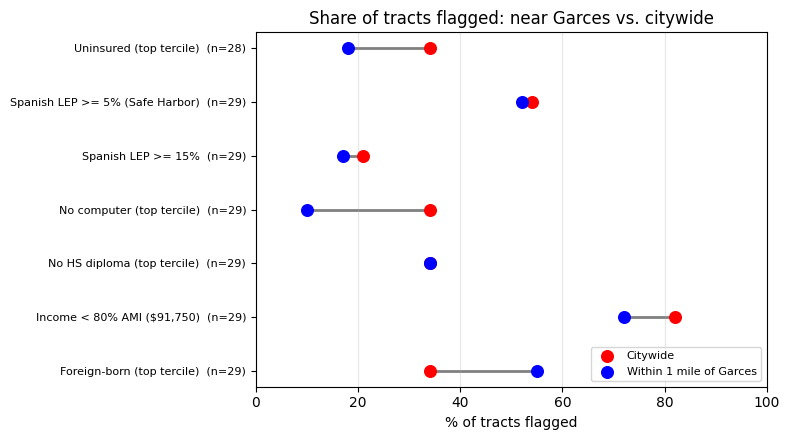

In [ ]:
# ===== VISUAL 1: Buffer vs. citywide dumbbell =====
s = summary.iloc[::-1]
y = np.arange(len(s))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hlines(y, s['% city tracts flagged'], s['% buffer tracts flagged'], color='gray', linewidth=2, zorder=1)
ax.scatter(s['% city tracts flagged'], y, color='red', s=70, label='Citywide', zorder=3)
ax.scatter(s['% buffer tracts flagged'], y, color='blue', s=70, label='Within 1 mile of Garces', zorder=3)
ax.set_yticks(y)
ax.set_yticklabels([f"{name}  (n={n})" for name, n in zip(s.index, s['Tracts in buffer'])], fontsize=8)
ax.set_xlabel('% of tracts flagged')
ax.set_title('Share of tracts flagged: near Garces vs. citywide')
ax.set_xlim(0, 100)
ax.grid(axis='x', alpha=0.3)
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
# ===== The "double burden" count: buffer tracts that are high-need AND low-income =====
def double_burden(df, col, need_rule):
    in_buf = df.intersects(buf)
    hit = need_rule(df[col]) & (df['median_hh_income'] < 91750)
    return int(hit[in_buf].sum()), int(in_buf.sum()), int(hit.sum()), len(df)

for name, df, col, rule in [
    ('Uninsured',    biv2_valid, 'pct_uninsured',      top_tercile),
    ('Spanish LEP',  biv_valid,  'pct_lep_spanish_hh', lambda s: s >= 5),
    ('No computer',  biv3_valid, 'pct_no_computer',    top_tercile),
    ('No HS diploma', biv4_valid, 'pct_no_hs',         top_tercile),
]:
    b, nb, c, nc = double_burden(df, col, rule)
    print(f"{name:14s} buffer: {b}/{nb} tracts low-income + high-need | citywide: {c}/{nc}")

for df, col in [(biv2_valid, 'pct_uninsured'), (biv_valid, 'pct_lep_spanish_hh'),
                (biv3_valid, 'pct_no_computer'), (biv4_valid, 'pct_no_hs')]:
    hi = df['pct_foreign_born'] >= df['pct_foreign_born'].quantile(0.66)
    print(f"{col}: high-immigrant tracts {df.loc[hi, col].median():.1f} vs other tracts {df.loc[~hi, col].median():.1f}")

Uninsured      buffer: 5/28 tracts low-income + high-need | citywide: 127/374
Spanish LEP    buffer: 10/29 tracts low-income + high-need | citywide: 176/383
No computer    buffer: 3/29 tracts low-income + high-need | citywide: 127/383
No HS diploma  buffer: 10/29 tracts low-income + high-need | citywide: 128/383
pct_uninsured: high-immigrant tracts 10.0 vs other tracts 9.7
pct_lep_spanish_hh: high-immigrant tracts 8.2 vs other tracts 4.5
pct_no_computer: high-immigrant tracts 6.5 vs other tracts 7.2
pct_no_hs: high-immigrant tracts 12.7 vs other tracts 9.4


**Takeaway:** *(near Garces, the share of low-income, high-need tracts is below the citywide share for uninsured, LEP, and no-computer, and about equal for no HS diploma.)*

## **4. Maps**

### **Map 1: Uninsured adults x income**

% adults aged 18-64 lacking health insurance, tract-level modeled estimates (CDC PLACES, ACCESS2). No federal "safe harbor"-style threshold exists for insurance status, so the uninsured rate is classified using terciles (33rd/66th percentile) across Philly tracts. Income uses the HUD FY2024 AMI bands, the same as the other maps.

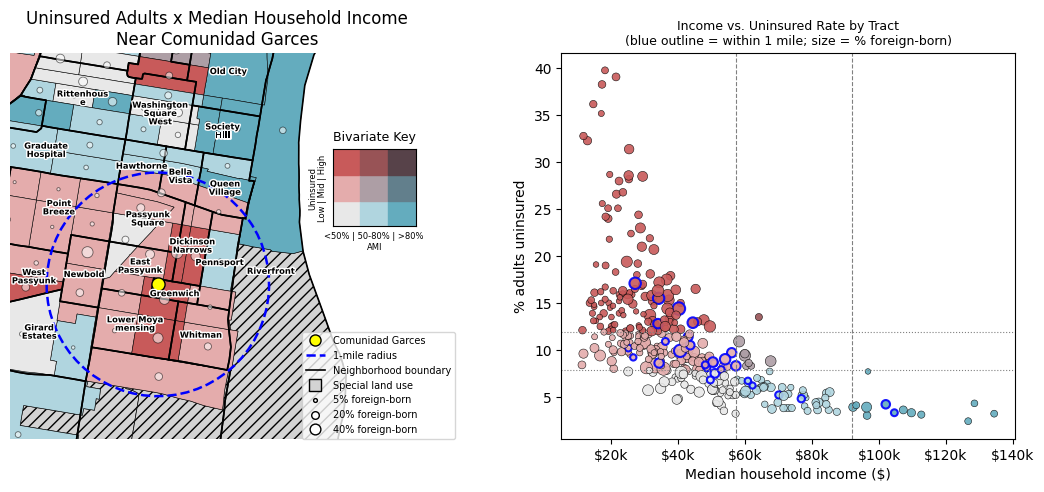

Tercile cutoffs: 33rd percentile = 7.8%, 66th percentile = 11.9%

Low (bottom third): n=124 tracts, range 2.4%-7.8%, mean 5.7%
Mid (middle third): n=123 tracts, range 7.9%-11.9%, mean 9.8%
High (top third): n=127 tracts, range 12.0%-39.8%, mean 17.4%


In [ ]:
# ===== Map 1 =====
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={'width_ratios': [1, 0.9]})

biv2_missing.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.5, hatch='///')
biv2_valid.plot(ax=ax, color=biv2_valid['biv_color'], edgecolor='black', linewidth=0.4)

add_foreign_born_bubbles(ax, biv2_valid, scale=1.5)   # smaller scale: Map 1 is zoomed out

buffer_1mi.plot(ax=ax, color='none', edgecolor='blue', linewidth=1.8, linestyle='--', zorder=4)
ax.scatter(garces_lon, garces_lat, marker='o', color='yellow', s=90, zorder=5, edgecolor='black')

xlim = (garces_lon - 0.025, garces_lon + 0.045)
ylim = (garces_lat - 0.02, garces_lat + 0.03)

# neighborhood outlines + labels
texts = add_neighborhood_labels(ax, xlim, ylim, names=keep)

ax.set_xlim(*xlim)
ax.set_ylim(*ylim)

ax.set_title('Uninsured Adults x Median Household Income\nNear Comunidad Garces')
ax.axis('off')

point = Line2D([0], [0], label='Comunidad Garces', marker='o', markersize=8,
               markeredgecolor='black', markerfacecolor='yellow', linestyle='')
buffer_handle = Line2D([0], [0], label='1-mile radius', color='blue',
                       linewidth=1.8, linestyle='--')
neigh_handle = Line2D([0], [0], label='Neighborhood boundary', color='black', linewidth=1.2)
no_data = Line2D([0], [0], label='Special land use', marker='s', markersize=8,
                 markerfacecolor='lightgray', markeredgecolor='black', linestyle='')

ax.legend(handles=[point, buffer_handle, neigh_handle, no_data] + foreign_born_legend_handles(scale=1.5),
          loc='lower right', bbox_to_anchor=(1.075, 0), borderaxespad=0, fontsize=7)

legend_ax = ax.inset_axes([0.78, 0.55, 0.20, 0.20])
for income_c in range(3):
    for uninsured_c in range(3):
        legend_ax.add_patch(plt.Rectangle((income_c, uninsured_c), 1, 1,
                                           color=bivariate_colors[(income_c, uninsured_c)]))
legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)
legend_ax.set_xticks([])
legend_ax.set_yticks([])
legend_ax.set_xlabel('<50% | 50-80% | >80%\nAMI', fontsize=6)
legend_ax.set_ylabel('Uninsured\nLow | Mid | High', fontsize=6)
legend_ax.set_title('Bivariate Key', fontsize=9)

# Scatterplot: income vs. uninsured, same colors as the map
in_buffer = biv2_valid.intersects(buffer_1mi.iloc[0])

ax2.scatter(biv2_valid['median_hh_income'], biv2_valid['pct_uninsured'],
            c=biv2_valid['biv_color'], s=15 + biv2_valid['pct_foreign_born'].fillna(0) * 1.5,
            edgecolor=np.where(in_buffer, 'blue', 'black'),
            linewidth=np.where(in_buffer, 1.5, 0.4), alpha=0.9)

# class boundaries
for x in (57350, 91750):
    ax2.axvline(x, color='gray', linestyle='--', linewidth=0.8)
for y in (q33, q66):
    ax2.axhline(y, color='gray', linestyle=':', linewidth=0.8)

ax2.set_xlabel('Median household income ($)')
ax2.set_ylabel('% adults uninsured')
ax2.set_title('Income vs. Uninsured Rate by Tract\n(blue outline = within 1 mile; size = % foreign-born)', fontsize=9)
ax2.xaxis.set_major_formatter(lambda x, _: f'${x/1000:.0f}k')

plt.tight_layout()
plt.show()

# Tercile boundaries and ranges for uninsured adults
print(f"Tercile cutoffs: 33rd percentile = {q33:.1f}%, 66th percentile = {q66:.1f}%\n")

for cls, label in [(0, 'Low (bottom third)'), (1, 'Mid (middle third)'), (2, 'High (top third)')]:
    subset = biv2_valid[biv2_valid['uninsured_class'] == cls]['pct_uninsured']
    print(f"{label}: n={len(subset)} tracts, "
          f"range {subset.min():.1f}%-{subset.max():.1f}%, "
          f"mean {subset.mean():.1f}%")

**Map 1 takeaway:** Near Garces, coverage gaps are less concentrated than citywide: 5 of 28 tracts within a mile (18%) are both low-income and in the top third for uninsured adults, about half the citywide share of 34%. Uninsured is the CDC PLACES modeled estimate for adults 18-64, split into terciles. The highest rates are farther away, which is where the Race St Clinic and mobile health units extend care.

*Note: Map 1 uses 2015 tract boundaries and 2011-2015 income, so its buffer contains 28 tracts rather than the 29 in Maps 2-4.*

### **Map 2: Spanish LEP x income**

**Limited English Proficiency (LEP):** Spanish-speaking households that are "limited English speaking" (no one 14+ speaks English "very well").

* **LEP threshold:** DOJ/HHS Title VI "Safe Harbor" (following Executive Order 13166): written translation is required for each eligible LEP language group that is 5 percent or 1,000 people, whichever is less, of the population eligible to be served. For a tract-level map, 5% household LEP is the "significant population" trigger. (U.S. Department of Health and Human Services)
* **Income:** HUD Area Median Income (AMI), FY2024, 4-person household, Philadelphia-Camden-Wilmington MSA: 30% = $34,400; very low (50%) = $57,350; 60% = $68,820; low (80%) = $91,750. ACS median household income is not size-adjusted, so bucketing against the 4-person benchmark is a simplification. (HUD)

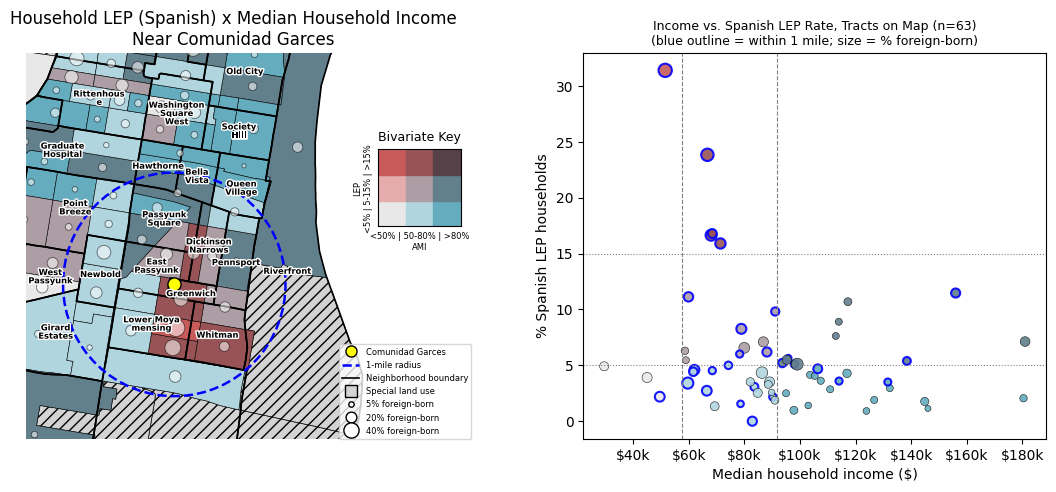

In [ ]:
# ===== Map 2 =====
xlim = (garces_lon - 0.025, garces_lon + 0.045)
ylim = (garces_lat - 0.02, garces_lat + 0.03)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={'width_ratios': [1, 0.9]})

# 1. data layers
biv_missing.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.5, hatch='///')
biv_valid.plot(ax=ax, color=biv_valid['biv_color'], edgecolor='black', linewidth=0.4)
add_foreign_born_bubbles(ax, biv_valid, scale=3)

# 2. buffer + site
buffer_1mi.plot(ax=ax, color='none', edgecolor='blue', linewidth=1.8, linestyle='--', zorder=4)
ax.scatter(garces_lon, garces_lat, marker='o', color='yellow', s=90, zorder=5, edgecolor='black')

# 3. neighborhood outlines + labels (ONE call only)
texts = add_neighborhood_labels(ax, xlim, ylim, names=keep)

# 4. limits
ax.set_xlim(*xlim)
ax.set_ylim(*ylim)

ax.set_title('Household LEP (Spanish) x Median Household Income\nNear Comunidad Garces')
ax.axis('off')

# 5. main legend
point = Line2D([0], [0], label='Comunidad Garces', marker='o', markersize=8,
               markeredgecolor='black', markerfacecolor='yellow', linestyle='')
buffer_handle = Line2D([0], [0], label='1-mile radius', color='blue',
                       linewidth=1.8, linestyle='--')
neigh_handle = Line2D([0], [0], label='Neighborhood boundary', color='black', linewidth=1.2)
no_data = Line2D([0], [0], label='Special land use', marker='s', markersize=8,
                 markerfacecolor='lightgray', markeredgecolor='black', linestyle='')
ax.legend(handles=[point, buffer_handle, neigh_handle, no_data] + foreign_born_legend_handles(scale=3),
          loc='lower right', bbox_to_anchor=(1.075, 0), borderaxespad=0, fontsize=6)

# 6. bivariate key
legend_ax = ax.inset_axes([0.85, 0.55, 0.20, 0.20])
for income_c in range(3):
    for lep_c in range(3):
        legend_ax.add_patch(plt.Rectangle((income_c, lep_c), 1, 1,
                                          color=bivariate_colors[(income_c, lep_c)]))
legend_ax.set_xlim(0, 3); legend_ax.set_ylim(0, 3)
legend_ax.set_xticks([]); legend_ax.set_yticks([])
legend_ax.set_xlabel('<50% | 50-80% | >80%\nAMI', fontsize=6)
legend_ax.set_ylabel('LEP\n<5% | 5-15% | >15%', fontsize=6)
legend_ax.set_title('Bivariate Key', fontsize=9)

view = biv_valid.cx[xlim[0]:xlim[1], ylim[0]:ylim[1]]     # tracts that appear in the zoomed map

add_scatter(ax2, view, 'pct_lep_spanish_hh', '% Spanish LEP households',
            hlines=(5, 15), title=f'Income vs. Spanish LEP Rate, Tracts on Map (n={len(view)})')

plt.show()

**Map 2 takeaway:** A third of the service area has a language-access need: 10 of 29 tracts (34%) are both low-income and above the 5% Title VI Safe Harbor threshold for Spanish LEP households, versus 46% citywide. LEP here means households where no one 14+ speaks English "very well." That is enough to justify ESL and language-access services, and the tracts with the highest rates are mostly outside the buffer, so online classes help reach them.

### **Map 3: No home computer x income**

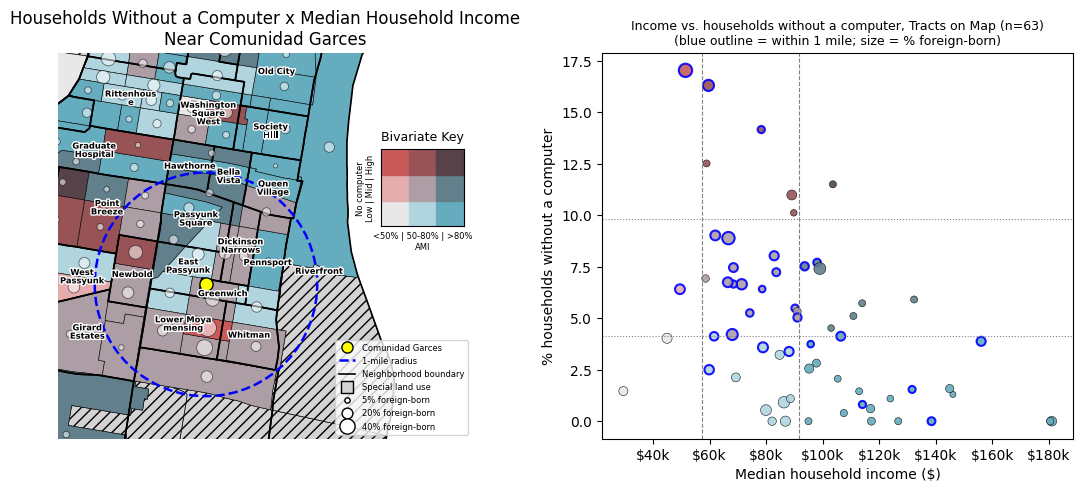

Tercile cutoffs for pct_no_computer: 33rd = 4.1%, 66th = 9.8%
  Low: n=127, range 0.0%-4.1%, mean 2.0%
  Mid: n=126, range 4.2%-9.8%, mean 6.7%
  High: n=130, range 10.0%-37.5%, mean 15.5%


In [ ]:
# ===== Map 3 =====
biv3_valid, biv3_missing = plot_tercile_bivariate(
    biv3, 'pct_no_computer',
    'Households Without a Computer x Median Household Income\nNear Comunidad Garces',
    'No computer\nLow | Mid | High',
    '% households without a computer')

**Map 3 takeaway:** Digital need near the site is narrow: only 3 of 29 tracts (10%) are low-income and in the top third for households without a computer, versus 33% citywide. Digital literacy classes may therefore serve a smaller group than the other services.

### **Map 4: No HS diploma x income**

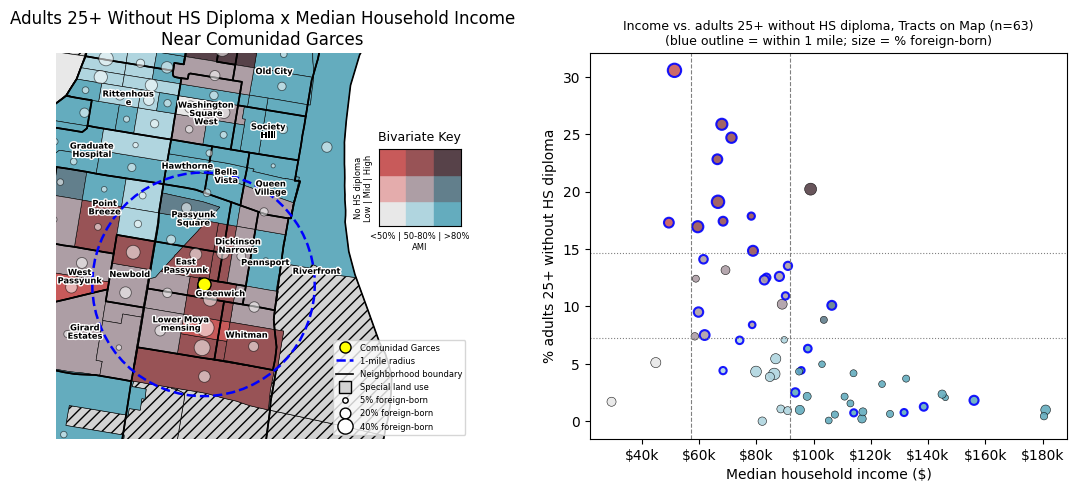

Tercile cutoffs for pct_no_hs: 33rd = 7.3%, 66th = 14.7%
  Low: n=127, range 0.0%-7.3%, mean 3.5%
  Mid: n=126, range 7.3%-14.7%, mean 10.7%
  High: n=130, range 14.7%-49.5%, mean 23.6%


In [ ]:
# ===== Map 4 =====
biv4_valid, biv4_missing = plot_tercile_bivariate(
    biv4, 'pct_no_hs',
    'Adults 25+ Without HS Diploma x Median Household Income\nNear Comunidad Garces',
    'No HS diploma\nLow | Mid | High',
    '% adults 25+ without HS diploma')

**Map 4 takeaway:** Education is where the neighborhood looks most like the city: 10 of 29 tracts (34%) are low-income with a high share of adults 25+ without a diploma, matching the citywide 33%. This is the need where GED classes fit the site best.

## **5. Immigrant concentration and need**

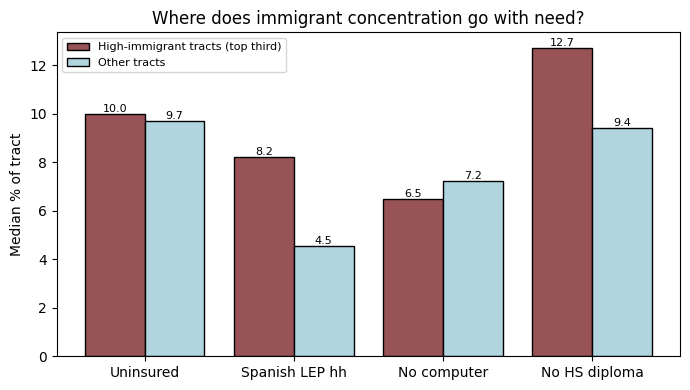

In [ ]:
# ===== VISUAL 2: Need in high-immigrant vs. other tracts =====
pairs = [(biv2_valid, 'pct_uninsured', 'Uninsured'),
         (biv_valid, 'pct_lep_spanish_hh', 'Spanish LEP hh'),
         (biv3_valid, 'pct_no_computer', 'No computer'),
         (biv4_valid, 'pct_no_hs', 'No HS diploma')]
hi_vals, lo_vals, labels = [], [], []
for df, col, lab in pairs:
    hi = df['pct_foreign_born'] >= df['pct_foreign_born'].quantile(0.66)
    hi_vals.append(df.loc[hi, col].median())
    lo_vals.append(df.loc[~hi, col].median())
    labels.append(lab)

x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(x - 0.2, hi_vals, 0.4, color='#985356', edgecolor='black', label='High-immigrant tracts (top third)')
b2 = ax.bar(x + 0.2, lo_vals, 0.4, color='#b0d5df', edgecolor='black', label='Other tracts')
ax.bar_label(b1, fmt='%.1f', fontsize=8)
ax.bar_label(b2, fmt='%.1f', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Median % of tract')
ax.set_title('Where does immigrant concentration go with need?')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

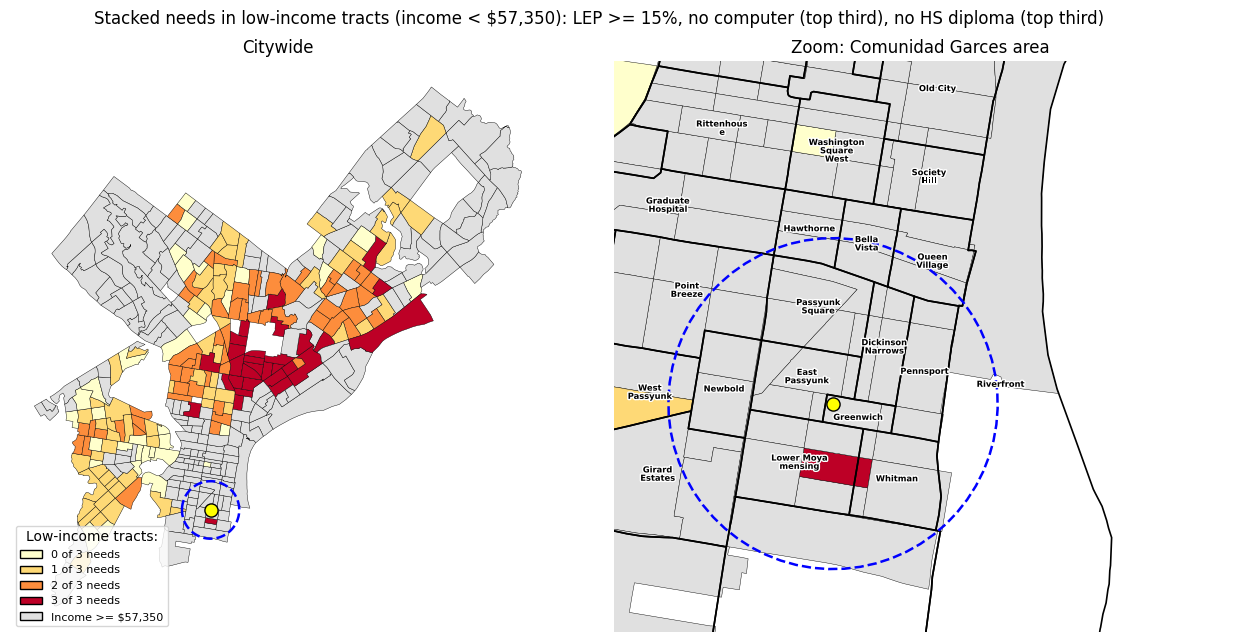

Low-income tracts: buffer 2/29, citywide 184/383
  0 needs: buffer 0, citywide 35
  1 needs: buffer 1, citywide 61
  2 needs: buffer 0, citywide 58
  3 needs: buffer 1, citywide 30
2+ needs: buffer 1/29 tracts, citywide 88/383 tracts


In [ ]:
# ===== VISUAL 3: Need-count map (low-income tracts, 2020 geometry) =====
# Adjust these thresholds if you want a different definition of "high need"
INCOME_CUT = 57350    # 50% AMI; use 91750 for the broader 80% AMI band
LEP_CUT = 15          # % Spanish LEP households

m = (biv_valid[['GEOID', 'geometry', 'pct_lep_spanish_hh', 'median_hh_income', 'pct_foreign_born']]
     .merge(biv3_valid[['GEOID', 'pct_no_computer']], on='GEOID', how='left')
     .merge(biv4_valid[['GEOID', 'pct_no_hs']], on='GEOID', how='left'))

m['f_lep'] = m['pct_lep_spanish_hh'] >= LEP_CUT
m['f_comp'] = m['pct_no_computer'] >= m['pct_no_computer'].quantile(0.66)
m['f_hs'] = m['pct_no_hs'] >= m['pct_no_hs'].quantile(0.66)
m['need_count'] = m[['f_lep', 'f_comp', 'f_hs']].sum(axis=1)
m['low_inc'] = m['median_hh_income'] < INCOME_CUT

palette = {0: '#ffffcc', 1: '#fed976', 2: '#fd8d3c', 3: '#bd0026'}
m['map_color'] = np.where(m['low_inc'], m['need_count'].map(palette), '#e0e0e0')

xlim = (garces_lon - 0.025, garces_lon + 0.045)
ylim = (garces_lat - 0.02, garces_lat + 0.03)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 6.5))
for ax_, zoom in [(axA, False), (axB, True)]:
    m.plot(ax=ax_, color=m['map_color'], edgecolor='black', linewidth=0.3)
    buffer_1mi.plot(ax=ax_, color='none', edgecolor='blue', linewidth=1.8, linestyle='--', zorder=4)
    ax_.scatter(garces_lon, garces_lat, color='yellow', edgecolor='black', s=90, zorder=5)
    if zoom:
        add_neighborhood_labels(ax_, xlim, ylim, names=keep)
        ax_.set_xlim(*xlim); ax_.set_ylim(*ylim)
        ax_.set_title('Zoom: Comunidad Garces area')
    else:
        ax_.set_title('Citywide')
    ax_.axis('off')

handles = [Patch(facecolor=palette[k], edgecolor='black',
                 label=f'{k} of 3 needs') for k in range(4)]
handles.append(Patch(facecolor='#e0e0e0', edgecolor='black', label=f'Income >= ${INCOME_CUT:,}'))
axA.legend(handles=handles, title='Low-income tracts:', loc='lower left', fontsize=8)
fig.suptitle(f'Stacked needs in low-income tracts (income < ${INCOME_CUT:,}): '
             f'LEP >= {LEP_CUT}%, no computer (top third), no HS diploma (top third)')
plt.tight_layout()
plt.show()

in_b = m.intersects(buf)
li = m['low_inc']
print(f"Low-income tracts: buffer {int((li & in_b).sum())}/{int(in_b.sum())}, citywide {int(li.sum())}/{len(m)}")
for k in range(4):
    kb = int(((m['need_count'] == k) & li & in_b).sum())
    kc = int(((m['need_count'] == k) & li).sum())
    print(f"  {k} needs: buffer {kb}, citywide {kc}")
print(f"2+ needs: buffer {int(((m['need_count'] >= 2) & li & in_b).sum())}/{int(in_b.sum())} tracts, "
      f"citywide {int(((m['need_count'] >= 2) & li).sum())}/{len(m)} tracts")

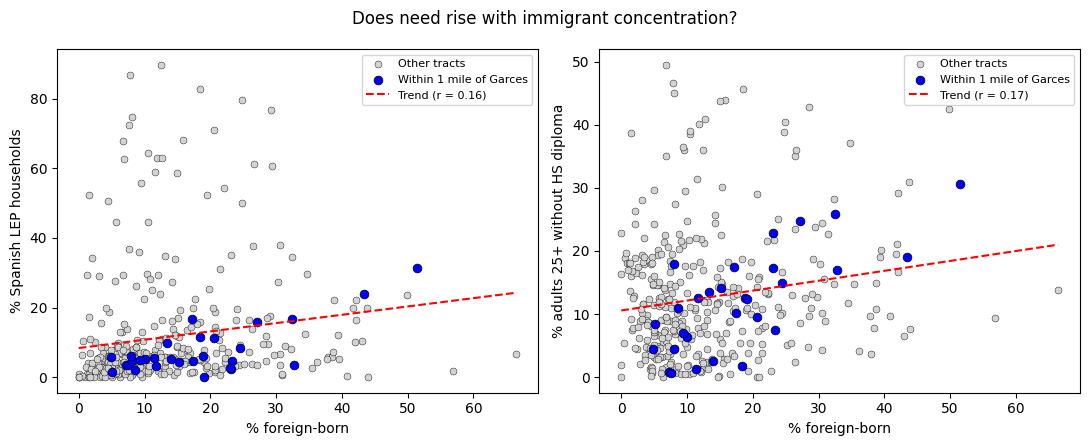

In [ ]:
# ===== VISUAL 4: Immigrant share vs. LEP and no-diploma (uses `m` from Visual 3) =====
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax_, col, lab in [(axes[0], 'pct_lep_spanish_hh', '% Spanish LEP households'),
                      (axes[1], 'pct_no_hs', '% adults 25+ without HS diploma')]:
    d = m.dropna(subset=['pct_foreign_born', col])
    inb = d.intersects(buf)
    ax_.scatter(d.loc[~inb, 'pct_foreign_born'], d.loc[~inb, col], color='lightgray',
                edgecolor='black', linewidth=0.3, s=25, label='Other tracts')
    ax_.scatter(d.loc[inb, 'pct_foreign_born'], d.loc[inb, col], color='blue',
                edgecolor='black', linewidth=0.5, s=40, label='Within 1 mile of Garces')
    slope, intercept = np.polyfit(d['pct_foreign_born'], d[col], 1)
    xs = np.linspace(d['pct_foreign_born'].min(), d['pct_foreign_born'].max(), 50)
    r = np.corrcoef(d['pct_foreign_born'], d[col])[0, 1]
    ax_.plot(xs, slope * xs + intercept, color='red', linestyle='--', label=f'Trend (r = {r:.2f})')
    ax_.set_xlabel('% foreign-born')
    ax_.set_ylabel(lab)
    ax_.legend(fontsize=8)
fig.suptitle('Does need rise with immigrant concentration?')
plt.tight_layout()
plt.show()

**Takeaway:** *(describe the shape of the scatter, including any nonlinearity, and what the high-immigrant vs. other tracts comparison shows.)*

## **6. Neighborhood comparison: Lower Moyamensing vs. Passyunk Square**

In [ ]:
# ===== Interactive map (folium): Lower Moyamensing vs. Passyunk Square =====
NAMES = ['Lower Moyamensing', 'Passyunk Square']
sel = neigh[neigh['MAPNAME'].isin(NAMES)]

# round the numbers shown in the hover tooltip
tr = biv_valid[['GEOID', 'median_hh_income', 'pct_lep_spanish_hh', 'pct_foreign_born',
                'biv_color', 'geometry']].copy()
tr['median_hh_income'] = tr['median_hh_income'].round(0)
tr['pct_lep_spanish_hh'] = tr['pct_lep_spanish_hh'].round(1)
tr['pct_foreign_born'] = tr['pct_foreign_born'].round(1)

fmap = folium.Map(location=[garces_lat, garces_lon], zoom_start=15, tiles=None)

# Esri World Street Map needs no key (CARTO now requires a key; plain OSM blocks notebook frames)
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri, HERE, Garmin, OpenStreetMap contributors',
    name='Street map', show=True).add_to(fmap)
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri, Maxar, Earthstar Geographics', name='Aerial imagery', show=False).add_to(fmap)

# Map 2 colors, semi-transparent, with hover tooltips
folium.GeoJson(
    json.loads(tr.to_json()),            # to_json turns NaN into null, which browsers accept
    name='Tracts (Spanish LEP x income)',
    style_function=lambda f: {'fillColor': f['properties']['biv_color'], 'fillOpacity': 0.55,
                              'color': 'black', 'weight': 0.8},
    tooltip=folium.GeoJsonTooltip(
        fields=['median_hh_income', 'pct_lep_spanish_hh', 'pct_foreign_born'],
        aliases=['Median income ($)', '% Spanish LEP hh', '% foreign-born'])).add_to(fmap)

# neighborhood outlines (no fill, so the tract tooltips still work)
folium.GeoJson(
    json.loads(sel[['MAPNAME', 'geometry']].to_json()),
    name='Neighborhoods',
    style_function=lambda f: {'color': 'white', 'weight': 4, 'fill': False},
    tooltip=folium.GeoJsonTooltip(fields=['MAPNAME'], aliases=['Neighborhood'], sticky=False)).add_to(fmap)

# Garces and the 1-mile radius
folium.Circle([garces_lat, garces_lon], radius=1609.34, color='blue', weight=2,
              dash_array='8', fill=False, name='1-mile radius').add_to(fmap)
folium.CircleMarker([garces_lat, garces_lon], radius=8, color='black', weight=1.5,
                    fill=True, fill_color='yellow', fill_opacity=1,
                    tooltip='Comunidad Garces').add_to(fmap)

# zoom to the two neighborhoods
minx, miny, maxx, maxy = sel.total_bounds
fmap.fit_bounds([[miny, minx], [maxy, maxx]])

# small bivariate key (income across, LEP up; same layout as the Map 2 key)
rows_html = ''.join(
    '<div>' + ''.join(
        f'<span style="display:inline-block;width:18px;height:18px;background:{bivariate_colors[(i, v)]}"></span>'
        for i in range(3)) + '</div>'
    for v in (2, 1, 0))
key_html = ('<div style="position:fixed;bottom:25px;left:25px;z-index:9999;background:white;'
            'padding:6px 8px;border:1px solid gray;font-size:11px;line-height:1.2">'
            '<b>Spanish LEP x income</b><br>' + rows_html +
            '<span>income: low &rarr; high<br>LEP: low (bottom) &rarr; high (top)</span></div>')
fmap.get_root().html.add_child(folium.Element(key_html))

folium.LayerControl(collapsed=False).add_to(fmap)
fmap.save('neighborhood_map.html')          # shareable file; open in any browser
fmap                                        # displays inline in the notebook

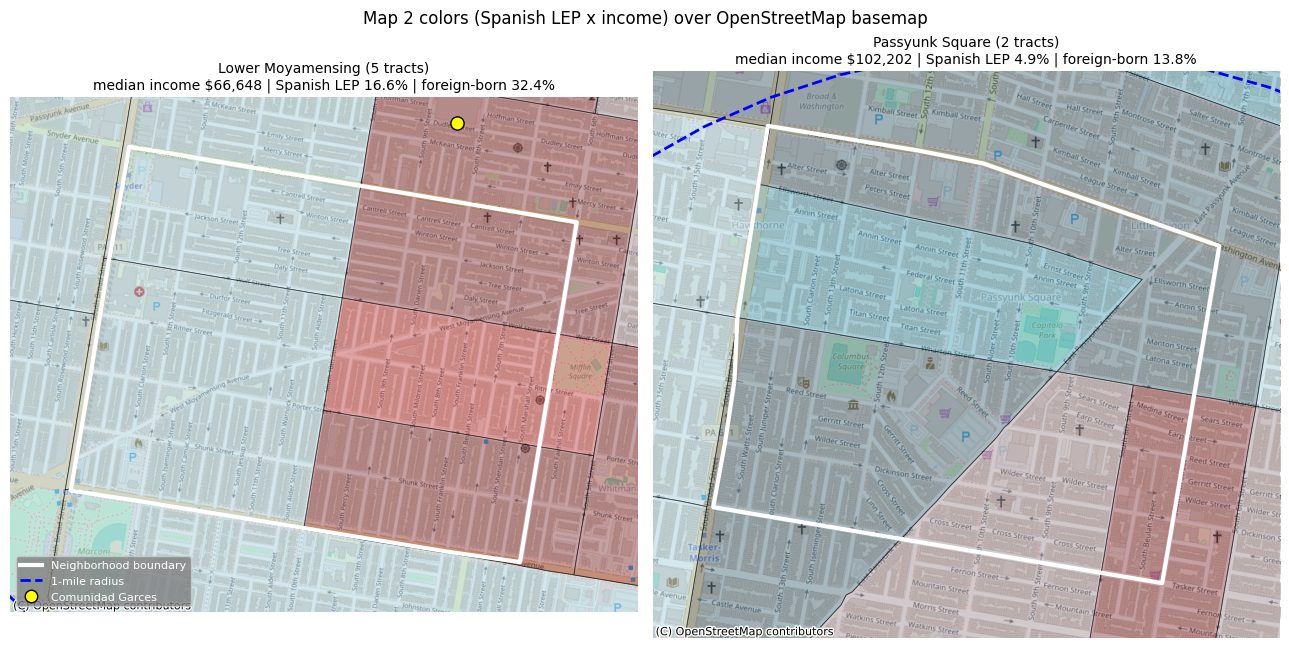

In [ ]:
# ===== Side-by-side: Lower Moyamensing vs. Passyunk Square, over an open basemap =====
import contextily as ctx

NAMES = ['Lower Moyamensing', 'Passyunk Square']

BASEMAP = ctx.providers.OpenStreetMap.Mapnik
HEADERS = {'User-Agent': 'PhillyCommunityNeedMap/1.0 (contact: student@temple.edu; academic research)'}

# Basemap tiles are in Web Mercator (EPSG:3857), so project everything to match
tracts_3857 = biv_valid.to_crs(3857)
buffer_3857 = buffer_1mi.to_crs(3857)
garces_3857 = garces_point.to_crs(3857)
pts = biv_valid.geometry.representative_point()      # one interior point per tract (still lon/lat)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, name in zip(axes, NAMES):
    n = neigh[neigh['MAPNAME'] == name].dissolve()   # one polygon row, lon/lat
    n_3857 = n.to_crs(3857)

    # zoom to the neighborhood with a little padding
    minx, miny, maxx, maxy = n_3857.total_bounds
    padx, pady = (maxx - minx) * 0.12, (maxy - miny) * 0.12
    ax.set_xlim(minx - padx, maxx + padx)
    ax.set_ylim(miny - pady, maxy + pady)

    # Map 2 colors, semi-transparent so the basemap shows through
    tracts_3857.plot(ax=ax, color=tracts_3857['biv_color'], alpha=0.55, edgecolor='black', linewidth=0.6)
    n_3857.plot(ax=ax, color='none', edgecolor='white', linewidth=3)
    buffer_3857.plot(ax=ax, color='none', edgecolor='blue', linewidth=2, linestyle='--')
    garces_3857.plot(ax=ax, color='yellow', edgecolor='black', markersize=90, zorder=5)

    ctx.add_basemap(ax, source=BASEMAP, crs='EPSG:3857', headers=HEADERS)   # draws under the layers above
    ax.axis('off')

    # quick stats for tracts whose interior point falls inside the neighborhood
    inside = biv_valid[pts.within(n.geometry.iloc[0])]
    ax.set_title(f"{name} ({len(inside)} tracts)\n"
                 f"median income ${inside['median_hh_income'].median():,.0f} | "
                 f"Spanish LEP {inside['pct_lep_spanish_hh'].median():.1f}% | "
                 f"foreign-born {inside['pct_foreign_born'].median():.1f}%", fontsize=10)

axes[0].legend(handles=[
    Line2D([0], [0], color='white', linewidth=3, label='Neighborhood boundary'),
    Line2D([0], [0], color='blue', linewidth=2, linestyle='--', label='1-mile radius'),
    Line2D([0], [0], marker='o', color='none', markerfacecolor='yellow', markeredgecolor='black',
           markersize=9, label='Comunidad Garces')],
    loc='lower left', fontsize=8, facecolor='gray', framealpha=0.8, labelcolor='white')

fig.suptitle('Map 2 colors (Spanish LEP x income) over OpenStreetMap basemap', y=1.0)
plt.tight_layout()
plt.show()

In [ ]:
biv_valid[['pct_lep_spanish_hh', 'pct_foreign_born']].corr(method='spearman')

,pct_lep_spanish_hh,pct_foreign_born
pct_lep_spanish_hh,1.000000,0.346152
pct_foreign_born,0.346152,1.000000


**Takeaway:** *(say what the comparison shows: the median income, Spanish LEP, and foreign-born figures in the two panel titles, and how they differ.)*

## **7. Conclusion: what this means for how Garces reaches clients**

Comunidad Garces is in a comparatively higher-income, immigrant-rich part of South Philadelphia (17% foreign-born vs. 10% citywide; buffer median income about $79k vs. $59k citywide). Only 2 of 29 nearby tracts fall below 50% AMI, and just one combines three need indicators, compared with 88 of 383 tracts citywide that combine two or more. The greatest concentrations of need, especially for language and education, which track immigrant concentration across the city, lie outside the 1-mile radius. The site's location fits its immigrant community well, but its reach depends on serving clients from farther away, through mobile units, online classes, and partnerships.

## **Appendix**

### **A. Distributions of each variable**

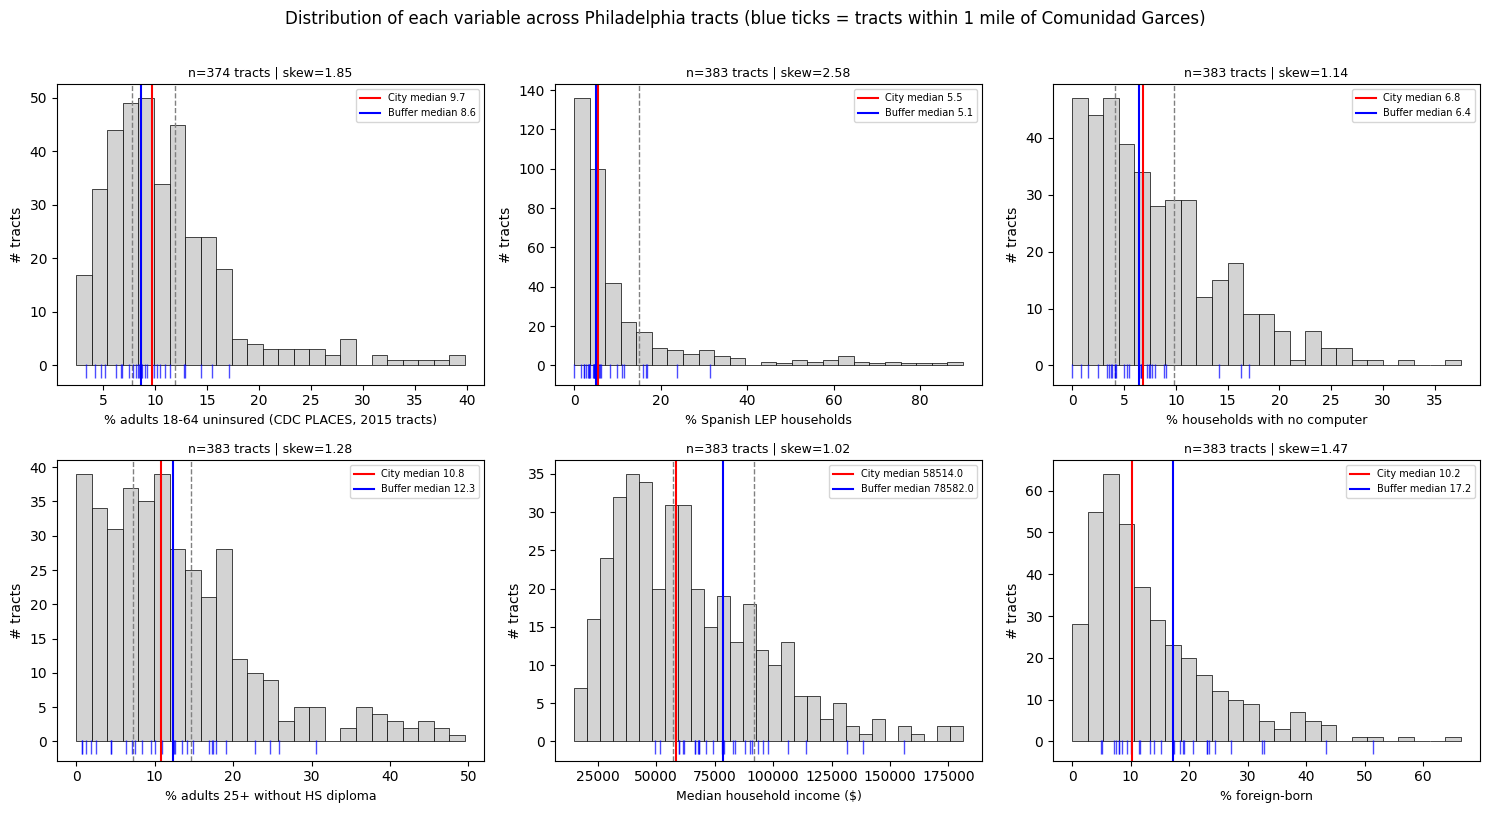

In [ ]:
# ===== Histograms of the main variables =====
# Gray bars = all Philly tracts. Blue ticks along the bottom = tracts inside the 1-mile buffer.
# Dashed lines = the cutoffs used on the maps.

# (frame, column, x-label, cutoffs, bins)
specs = [
    (biv2_valid, 'pct_uninsured',      '% adults 18-64 uninsured (CDC PLACES, 2015 tracts)', 'terciles', 25),
    (biv_valid,  'pct_lep_spanish_hh', '% Spanish LEP households',                           [5, 15],    25),
    (biv3_valid, 'pct_no_computer',    '% households with no computer',                      'terciles', 25),
    (biv4_valid, 'pct_no_hs',          '% adults 25+ without HS diploma',                    'terciles', 25),
    (biv_valid,  'median_hh_income',   'Median household income ($)',                        [57350, 91750], 30),
    (biv_valid,  'pct_foreign_born',   '% foreign-born',                                     None,       25),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (df, col, xlabel, cuts, bins) in zip(axes.ravel(), specs):
    vals = df[col].dropna()
    ax.hist(vals, bins=bins, color='lightgray', edgecolor='black', linewidth=0.5)

    if cuts == 'terciles':
        cuts = list(vals.quantile([0.33, 0.66]))
    for c in (cuts or []):
        ax.axvline(c, color='gray', linestyle='--', linewidth=1)

    # tracts inside the 1-mile buffer, drawn as ticks under the bars
    in_buf = df[df.intersects(buf)][col].dropna()
    ax.plot(in_buf, np.full(len(in_buf), -0.02 * ax.get_ylim()[1]), '|',
            color='blue', markersize=10, alpha=0.7, clip_on=False)

    ax.axvline(vals.median(), color='red', linewidth=1.5, label=f'City median {vals.median():.1f}')
    if len(in_buf):
        ax.axvline(in_buf.median(), color='blue', linewidth=1.5,
                   label=f'Buffer median {in_buf.median():.1f}')

    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_ylabel('# tracts')
    ax.set_title(f'n={len(vals)} tracts | skew={vals.skew():.2f}', fontsize=9)
    ax.legend(fontsize=7)

fig.suptitle('Distribution of each variable across Philadelphia tracts '
             '(blue ticks = tracts within 1 mile of Comunidad Garces)', y=1.01)
plt.tight_layout()
plt.show()

All six variables are right-skewed (skew of 1.0 to 2.6): most tracts cluster at low values, with a long tail of a few very high-need tracts. Spanish LEP is the most extreme (skew 2.58, with rates above 80% in a handful of tracts), so need is concentrated in a small number of tracts, not spread evenly, and medians describe the typical tract better than means.

### **B. Merge diagnostics**

#### Map 1 (uninsured x income x foreign-born, 2015-vintage tracts)

In [ ]:
# ===== Merge diagnostics for Map 1, on matching 2015-vintage tracts =====
check1 = phT_2015.merge(places_uninsured[['GEOID', 'pct_uninsured']], on='GEOID', how='outer', indicator=True)
print("Step 1 (2015-vintage tracts x uninsured):")
print(check1['_merge'].value_counts(), "\n")

check2 = check1.merge(acs_income_2015[['GEOID', 'median_hh_income']], on='GEOID', how='outer', indicator='_merge2')
print("Step 2 (+ 2015-vintage income):")
print(check2['_merge2'].value_counts(), "\n")

check3 = check2.merge(acs_fb_2015[['GEOID', 'pct_foreign_born']], on='GEOID', how='outer', indicator='_merge3')
print("Step 3 (+ 2015-vintage foreign-born):")
print(check3['_merge3'].value_counts(), "\n")

print("Right-only GEOIDs (should be empty or explainable):")
print("  step 2:", check2[check2['_merge2'] == 'right_only']['GEOID'].tolist())
print("  step 3:", check3[check3['_merge3'] == 'right_only']['GEOID'].tolist())

Step 1 (2015-vintage tracts x uninsured):
_merge
both          376
left_only       8
right_only      0
Name: count, dtype: int64 

Step 2 (+ 2015-vintage income):
_merge2
both          384
left_only       0
right_only      0
Name: count, dtype: int64 

Step 3 (+ 2015-vintage foreign-born):
_merge3
both          384
left_only       0
right_only      0
Name: count, dtype: int64 

Right-only GEOIDs (should be empty or explainable):
  step 2: []
  step 3: []


In [ ]:
# ===== Categorize missing tracts: Map 1 (uninsured x income) =====
def categorize_missing(missing_gdf, source_df, value_col, pop_threshold=200):
    """
    missing_gdf: rows from biv2_missing / biv_missing (has GEOID)
    source_df: the original pull (places_uninsured) with population info, if available
    value_col: the variable that's missing (e.g. 'pct_uninsured')
    """
    df = missing_gdf[['GEOID']].copy()
    df['tract_code'] = df['GEOID'].str[5:]
    df['is_special_tract'] = df['tract_code'].str.startswith(('98', '99'))

    if 'totalpopulation' in source_df.columns:
        df = df.merge(source_df[['GEOID', 'totalpopulation']], on='GEOID', how='left')
        df['low_population'] = df['totalpopulation'] < pop_threshold
    else:
        df['totalpopulation'] = np.nan
        df['low_population'] = False

    def bucket(row):
        if row['is_special_tract']:
            return 'special/non-residential tract'
        elif row['low_population']:
            return 'low population (likely suppressed)'
        elif pd.isna(row['totalpopulation']):
            return 'no population data available — investigate'
        else:
            return 'unexplained — investigate'

    df['category'] = df.apply(bucket, axis=1)
    return df

missing_uninsured = biv2_4326[biv2_4326['pct_uninsured'].isna()]
cat_uninsured = categorize_missing(missing_uninsured, places_uninsured, 'pct_uninsured')

print("Map 1 — missing 'pct_uninsured' tract breakdown:")
print(cat_uninsured['category'].value_counts(), "\n")
print(cat_uninsured.sort_values('category'))

Map 1 — missing 'pct_uninsured' tract breakdown:
category
special/non-residential tract                 7
no population data available — investigate    1
Name: count, dtype: int64 

         GEOID tract_code  is_special_tract  totalpopulation  low_population  \
4  42101005000     005000             False              NaN           False   
0  42101980400     980400              True              NaN           False   
1  42101980500     980500              True              NaN           False   
2  42101980900     980900              True              NaN           False   
3  42101980800     980800              True              NaN           False   
5  42101980600     980600              True              NaN           False   
6  42101980700     980700              True              NaN           False   
7  42101980300     980300              True              NaN           False   

                                     category  
4  no population data available — investigate  
0

**Merge diagnostics summary (Map 1, final):**

Step 1 (2015-vintage tracts x CDC PLACES uninsured): 376 matched, 8 left_only, 0 right_only. The CDC PLACES codebook (em5e-5hvn) documents these estimates as joinable with the 2015 census tract boundary file; switching from the original 2020-vintage shapefile to a matching 2015-vintage shapefile resolved the prior 358/50/18 mismatch almost entirely. The remaining 8 left_only tracts reflect standard small-population/CDC suppression, not a vintage or key error.

Step 2 (+ ACS median household income, 2011-2015 5-year estimate): 384 matched, 0 left_only, 0 right_only. Pulling income data from the ACS vintage matching phT_2015 (rather than the 2018-2022/2020-vintage estimate used in Map 2) fully resolved the earlier 21/45 mismatch, a perfect merge across all 384 tracts.

Verdict: both merge steps are now fully explained and, on the income side, fully resolved. The 8 remaining CDC gaps are documented, expected suppression, not an error. This demonstrates the workflow requested: check the codebook for tract vintage, obtain a matching shapefile, and merge, applied to two independently-sourced datasets (CDC PLACES and ACS).

Note: because Map 1 uses the 2011-2015 ACS estimate for income (to match CDC's tract vintage) while Map 2 uses the 2018-2022 ACS estimate (to match its LEP variable's vintage), the two maps' income figures reflect different survey periods, though both apply the same HUD AMI classification thresholds.

#### Map 2 (Spanish LEP x income x foreign-born, 2020-vintage tracts)

In [ ]:
# ===== Merge diagnostics for Map 2 =====
print("Duplicate GEOIDs check:")
print(f"  phT: {phT['GEOID'].duplicated().sum()} duplicates")
print(f"  acs_lep_hh: {acs_lep_hh['GEOID'].duplicated().sum()} duplicates")
print(f"  acs_income: {acs_income['GEOID'].duplicated().sum()} duplicates")
print(f"  acs_fb: {acs_fb['GEOID'].duplicated().sum()} duplicates\n")

# Step 1: tracts x LEP
check1 = phT.merge(acs_lep_hh[['GEOID', 'pct_lep_spanish_hh']], on='GEOID', how='outer', indicator=True)
print("Step 1 (tracts x LEP):")
print(check1['_merge'].value_counts(), "\n")

print("Left-only GEOIDs (Philly tracts with no LEP row — expected, becomes 'missing' hatch):")
print(f"  n = {(check1['_merge'] == 'left_only').sum()}\n")

print("Right-only GEOIDs (LEP rows that aren't Philly tracts — should be empty):")
print(check1[check1['_merge'] == 'right_only']['GEOID'].tolist(), "\n")

# Step 2: + income
check2 = check1.merge(acs_income[['GEOID', 'median_hh_income']], on='GEOID', how='outer', indicator='_merge2')
print("Step 2 (+ income):")
print(check2['_merge2'].value_counts(), "\n")

print("Right-only GEOIDs (income rows that aren't Philly tracts — should be empty):")
print(check2[check2['_merge2'] == 'right_only']['GEOID'].tolist(), "\n")

# Step 3: + foreign-born
check3 = check2.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='outer', indicator='_merge3')
print("Step 3 (+ foreign-born):")
print(check3['_merge3'].value_counts(), "\n")

print("Right-only GEOIDs (foreign-born rows that aren't Philly tracts — should be empty):")
print(check3[check3['_merge3'] == 'right_only']['GEOID'].tolist(), "\n")

# Row count sanity check
print(f"phT rows: {len(phT)}")
print(f"check3 rows: {len(check3)}")
assert len(check3) == len(phT) + (check3['_merge3'] == 'right_only').sum() + (check3['_merge2'] == 'right_only').sum(), \
    "Row count mismatch — investigate duplicates or fan-out"

print("\nMissingness cross-tab (LEP status x income status):")
print(pd.crosstab(
    check3['pct_lep_spanish_hh'].isna().map({True: 'LEP missing', False: 'LEP present'}),
    check3['median_hh_income'].isna().map({True: 'income missing', False: 'income present'})
))

Duplicate GEOIDs check:
  phT: 0 duplicates
  acs_lep_hh: 0 duplicates
  acs_income: 0 duplicates
  acs_fb: 0 duplicates

Step 1 (tracts x LEP):
_merge
both          408
left_only       0
right_only      0
Name: count, dtype: int64 

Left-only GEOIDs (Philly tracts with no LEP row — expected, becomes 'missing' hatch):
  n = 0

Right-only GEOIDs (LEP rows that aren't Philly tracts — should be empty):
[] 

Step 2 (+ income):
_merge2
both          408
left_only       0
right_only      0
Name: count, dtype: int64 

Right-only GEOIDs (income rows that aren't Philly tracts — should be empty):
[] 

Step 3 (+ foreign-born):
_merge3
both          408
left_only       0
right_only      0
Name: count, dtype: int64 

Right-only GEOIDs (foreign-born rows that aren't Philly tracts — should be empty):
[] 

phT rows: 408
check3 rows: 408

Missingness cross-tab (LEP status x income status):
median_hh_income    income missing  income present
pct_lep_spanish_hh                                
LEP missing 

In [ ]:
# ===== Categorize missing tracts: Map 2 (LEP x income) =====
# acs_lep_hh has no population column, so "low population" is approximated with the LEP
# universe denominator (C16002_001E = total households).
missing_lep = biv_4326[biv_4326['pct_lep_spanish_hh'].isna()]

df_lep = missing_lep[['GEOID']].copy()
df_lep['tract_code'] = df_lep['GEOID'].str[5:]
df_lep['is_special_tract'] = df_lep['tract_code'].str.startswith(('98', '99'))
df_lep = df_lep.merge(acs_lep_hh[['GEOID', 'C16002_001E']], on='GEOID', how='left')
df_lep['low_household_base'] = df_lep['C16002_001E'] < 50  # tune threshold as needed

def bucket_lep(row):
    if row['is_special_tract']:
        return 'special/non-residential tract'
    elif pd.isna(row['C16002_001E']):
        return 'no ACS row at all — investigate (vintage/GEOID mismatch?)'
    elif row['low_household_base']:
        return 'low household base (likely suppressed/unreliable)'
    else:
        return 'unexplained — investigate'

df_lep['category'] = df_lep.apply(bucket_lep, axis=1)

print("Map 2 — missing 'pct_lep_spanish_hh' tract breakdown:")
print(df_lep['category'].value_counts(), "\n")
print(df_lep.sort_values('category'))

Map 2 — missing 'pct_lep_spanish_hh' tract breakdown:
category
special/non-residential tract                        19
low household base (likely suppressed/unreliable)     1
Name: count, dtype: int64 

          GEOID tract_code  is_special_tract  C16002_001E  low_household_base  \
13  42101036901     036901             False            0                True   
0   42101980003     980003              True            0                True   
17  42101989300     989300              True            0                True   
16  42101980901     980901              True            0                True   
15  42101980002     980002              True            0                True   
14  42101980001     980001              True            0                True   
12  42101989200     989200              True            0                True   
11  42101980702     980702              True            0                True   
10  42101980500     980500              True            0           

**Merge diagnostics summary (Map 2):**

* 0 left_only, 0 right_only at the merge step: every phT tract matched exactly one acs_lep_hh row. The merge itself is fully correct.
* The 20 "missing" tracts appearing later are NaN values within a successful merge: 19 are special/non-residential tracts with 0 reported households, and 1 (GEOID 42101036901) was a divide-by-zero artifact in the pct_lep_spanish_hh calculation (0 LEP households / 0 total households), now handled explicitly rather than silently producing NaN.

#### Maps 3 and 4

In [ ]:
# ===== Merge diagnostics for Map 3 (no computer) =====
print(f"acs_dig: {acs_dig['GEOID'].duplicated().sum()} duplicate GEOIDs\n")

check = base.merge(acs_dig[['GEOID', 'pct_no_computer']], on='GEOID', how='outer', indicator=True)
print("Map 3 (tracts x no-computer):")
print(check['_merge'].value_counts(), "\n")
print("Right-only GEOIDs (should be empty):", check[check['_merge'] == 'right_only']['GEOID'].tolist())

check_fb = base.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='outer', indicator=True)
print("\nMap 3 (tracts x foreign-born):")
print(check_fb['_merge'].value_counts(), "\n")

# ===== Merge diagnostics for Map 4 (no HS diploma) =====
print(f"acs_ged: {acs_ged['GEOID'].duplicated().sum()} duplicate GEOIDs\n")

check = base.merge(acs_ged[['GEOID', 'pct_no_hs']], on='GEOID', how='outer', indicator=True)
print("Map 4 (tracts x no-HS-diploma):")
print(check['_merge'].value_counts(), "\n")
print("Right-only GEOIDs (should be empty):", check[check['_merge'] == 'right_only']['GEOID'].tolist())

check_fb = base.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='outer', indicator=True)
print("\nMap 4 (tracts x foreign-born):")
print(check_fb['_merge'].value_counts(), "\n")

acs_dig: 0 duplicate GEOIDs

Map 3 (tracts x no-computer):
_merge
both          408
left_only       0
right_only      0
Name: count, dtype: int64 

Right-only GEOIDs (should be empty): []

Map 3 (tracts x foreign-born):
_merge
both          408
left_only       0
right_only      0
Name: count, dtype: int64 

acs_ged: 0 duplicate GEOIDs

Map 4 (tracts x no-HS-diploma):
_merge
both          408
left_only       0
right_only      0
Name: count, dtype: int64 

Right-only GEOIDs (should be empty): []

Map 4 (tracts x foreign-born):
_merge
both          408
left_only       0
right_only      0
Name: count, dtype: int64 



## Class notes

* make histogram of main variable to see distribution
* be clear about measurement -- always include in note/caption/interpretation
* ideally, map multiple measures of the same thing, i.e., "triangulate"
* standardize to get meaningful interpretations -- "per sq km" or "pop per capita"
* useful: side-by-side, overlays, annotations, classification method

## Notes for PS2 -> PS3
for healthcare maps
* add Sonrisa location

for education maps
* map multiple measures of the same thing
  * add map with data for not just Spanish speakers
  * add years since arrival map
* focus on interpretation
  * nonlinear relationship
  * association with latino immigrants
* make scatterplot only south philly census tracts
* raster pictures to compare different neighbourhoods (Lower Moyamensing vs Passyunk Square)